# 07 · Claim reader: regex vs TF-IDF vs DistilBERT
**Owner:** Rakshita

Phase 2. In Phase 1 the regex parser read the hypothesis, so it only knows the five Corr2Cause wordings. Here we
train two **readers** that predict the claim type (direct cause, indirect cause, collider, confounder) from the
sentence:
* **TF-IDF + Logistic Regression**, the classical ML reader
* **DistilBERT**, a fine-tuned transformer

The two variables are still the single capital letters (A–F after notebook 06). The readers only learn wordings,
never labels. The PC step from notebook 02 stays the same and does the causal reasoning in notebook 09.

In [1]:
# ─── IMPORTS ─────
import sys
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sys.path.insert(0, "../src")
from c2c.parsing import parse_hypothesis
from c2c.reader import WORDINGS, wording_examples
from c2c.transformer import load_model, fine_tune, predict_proba

In [2]:
# ─── LOAD DATA ─────
test_sets = pd.read_csv("../data/processed/test_sets.csv")

# training sentences: every wording in src/c2c/reader.py with every pair of A-F
examples = wording_examples()
train = examples[examples["part"] == "train"]
validation = examples[examples["part"] == "validation"]
print(train.shape, validation.shape)

(600, 3) (120, 3)


In [3]:
# the wordings: the original templates plus our own; the last one of each type is held out for validation
for relation in WORDINGS:
    print(relation)
    for wording in WORDINGS[relation]:
        print("   ", wording)

direct_cause
    {x} directly causes {y}.
    {x} has a direct effect on {y}.
    {x} is a direct cause of {y}.
    {x} directly leads to {y}.
    {x} causes {y} with nothing in between.
    {x} directly changes {y}.
indirect_cause
    {x} causes something else which causes {y}.
    {x} is a cause for {y}, but not a direct one.
    {x} causes {y} through another variable.
    {x} has an indirect effect on {y}.
    {x} leads to {y} by way of a third variable.
    {x} is an indirect cause of {y}.
collider
    There exists at least one collider (i.e., common effect) of {x} and {y}.
    {x} and {y} have a common effect.
    {x} and {y} both cause a third variable.
    There is a variable that is caused by both {x} and {y}.
    {x} and {y} share a common effect.
    One variable is an effect of {x} and also of {y}.
confounder
    There exists at least one confounder (i.e., common cause) of {x} and {y}.
    {x} and {y} have a common cause.
    {x} and {y} are caused by the same variable.
   

None of our wordings use the words of the authors' paraphrase test ("affects", "influences", "mediator",
"together"), so the paraphrasing test set really is new wording for every reader.

In [4]:
# ─── STEP 1: REGEX READER (PHASE 1) ─────
test_sets = parse_hypothesis(test_sets)   # adds x, y and relation
test_sets = test_sets.rename(columns={"relation": "relation_regex"})

# share of claims the regex cannot read
test_sets["regex_unknown"] = test_sets["relation_regex"] == "unknown"
test_sets.groupby("test_set")["regex_unknown"].mean()

test_set
original           0.0
paraphrasing       1.0
refactorization    0.0
Name: regex_unknown, dtype: float64

The regex reads every original and renamed claim, but **none** of the reworded ones.

In [5]:
# ─── STEP 2: IS LEARNING THE ORIGINAL WORDINGS ENOUGH? ─────
# train on the five Corr2Cause templates only, then try our held-out validation wordings
original_only = wording_examples(original_only=True)

tfidf = TfidfVectorizer(token_pattern=r"\b\w+\b", ngram_range=(1, 2))
X_original = tfidf.fit_transform(original_only["hypothesis"])
X_val = tfidf.transform(validation["hypothesis"])

lr = LogisticRegression(max_iter=2000)
lr.fit(X_original, original_only["relation"])
print("TF-IDF, original wordings only:", accuracy_score(validation["relation"], lr.predict(X_val)))

TF-IDF, original wordings only: 0.75


In [6]:
# DistilBERT works with class numbers, so we give each claim type a number
relation_to_id = {"collider": 0, "confounder": 1, "direct_cause": 2, "indirect_cause": 3}
id_to_relation = {0: "collider", 1: "confounder", 2: "direct_cause", 3: "indirect_cause"}
RELATIONS = list(relation_to_id)   # the 4 claim types, in class order

tokenizer, bert = load_model(num_labels=4, seed=42)
fine_tune(bert, tokenizer, original_only["hypothesis"], original_only["relation"].map(relation_to_id), epochs=3, lr=3e-5, seed=42)

proba = predict_proba(bert, tokenizer, validation["hypothesis"])   # one probability per claim type
predicted = pd.Series(proba.argmax(axis=1)).map(id_to_relation)     # the most likely claim type
print("DistilBERT, original wordings only:", accuracy_score(validation["relation"], predicted))

epoch 1: mean loss 1.1188


epoch 2: mean loss 0.5084


epoch 3: mean loss 0.2143
DistilBERT, original wordings only: 0.5


Trained on the five templates only, TF-IDF reads 75% and DistilBERT only 50% of our held-out wordings. Five fixed
wordings are not enough, so both readers are trained on our extra wordings below.

In [7]:
# ─── STEP 3: TF-IDF + LOGISTIC REGRESSION READER ─────
tfidf = TfidfVectorizer(token_pattern=r"\b\w+\b", ngram_range=(1, 2))
X_train = tfidf.fit_transform(train["hypothesis"])
X_val = tfidf.transform(validation["hypothesis"])

lr = LogisticRegression(max_iter=2000)
lr.fit(X_train, train["relation"])
print("validation accuracy:", accuracy_score(validation["relation"], lr.predict(X_val)))

validation accuracy: 0.9166666666666666


In [8]:
# ─── STEP 4: DISTILBERT READER ─────
# 3 epochs, learning rate 3e-5, batch size 16
tokenizer, bert = load_model(num_labels=4, seed=42)
fine_tune(bert, tokenizer, train["hypothesis"], train["relation"].map(relation_to_id), epochs=3, lr=3e-5, seed=42)

proba = predict_proba(bert, tokenizer, validation["hypothesis"])
predicted = pd.Series(proba.argmax(axis=1)).map(id_to_relation)
print("validation accuracy:", accuracy_score(validation["relation"], predicted))

epoch 1: mean loss 0.8154


epoch 2: mean loss 0.0848


epoch 3: mean loss 0.0233
validation accuracy: 0.825


On our validation wordings TF-IDF scores higher (0.92 vs 0.83), because they share many words with the training
wordings. The real test is the authors' paraphrases, which neither reader has seen.

In [9]:
# ─── STEP 5: READ THE TEST CLAIMS ─────
test_sets["relation_tfidf"] = lr.predict(tfidf.transform(test_sets["hypothesis"]))

proba = predict_proba(bert, tokenizer, test_sets["hypothesis"])
test_sets["relation_bert"] = pd.Series(proba.argmax(axis=1)).map(id_to_relation).values
test_sets["bert_confidence"] = proba.max(axis=1)   # probability of the chosen claim type

# share of claims read correctly, per reader and test set
test_sets["regex"] = test_sets["relation_regex"] == test_sets["relation_true"]
test_sets["TF-IDF"] = test_sets["relation_tfidf"] == test_sets["relation_true"]
test_sets["DistilBERT"] = test_sets["relation_bert"] == test_sets["relation_true"]
test_sets.groupby("test_set")[["regex", "TF-IDF", "DistilBERT"]].mean().round(3)

,regex,TF-IDF,DistilBERT
test_set,,,
original,1.0,1.000,1.0
paraphrasing,0.0,0.668,1.0
refactorization,1.0,1.000,1.0


All three readers read the original and renamed claims perfectly. On the reworded claims the regex reads none,
TF-IDF reads 67% and DistilBERT reads all of them.

In [10]:
# precision, recall and F1 for every claim type on the reworded claims
paraphrasing = test_sets[test_sets["test_set"] == "paraphrasing"]
print("TF-IDF")
print(classification_report(paraphrasing["relation_true"], paraphrasing["relation_tfidf"], digits=3, zero_division=0))
print("DistilBERT")
print(classification_report(paraphrasing["relation_true"], paraphrasing["relation_bert"], digits=3, zero_division=0))

TF-IDF
                precision    recall  f1-score   support

      collider      0.000     0.000     0.000       373
    confounder      0.000     0.000     0.000       373
  direct_cause      1.000     1.000     1.000       750
indirect_cause      1.000     1.000     1.000       750

      accuracy                          0.668      2246
     macro avg      0.500     0.500     0.500      2246
  weighted avg      0.668     0.668     0.668      2246

DistilBERT
                precision    recall  f1-score   support

      collider      1.000     1.000     1.000       373
    confounder      1.000     1.000     1.000       373
  direct_cause      1.000     1.000     1.000       750
indirect_cause      1.000     1.000     1.000       750

      accuracy                          1.000      2246
     macro avg      1.000     1.000     1.000      2246
  weighted avg      1.000     1.000     1.000      2246



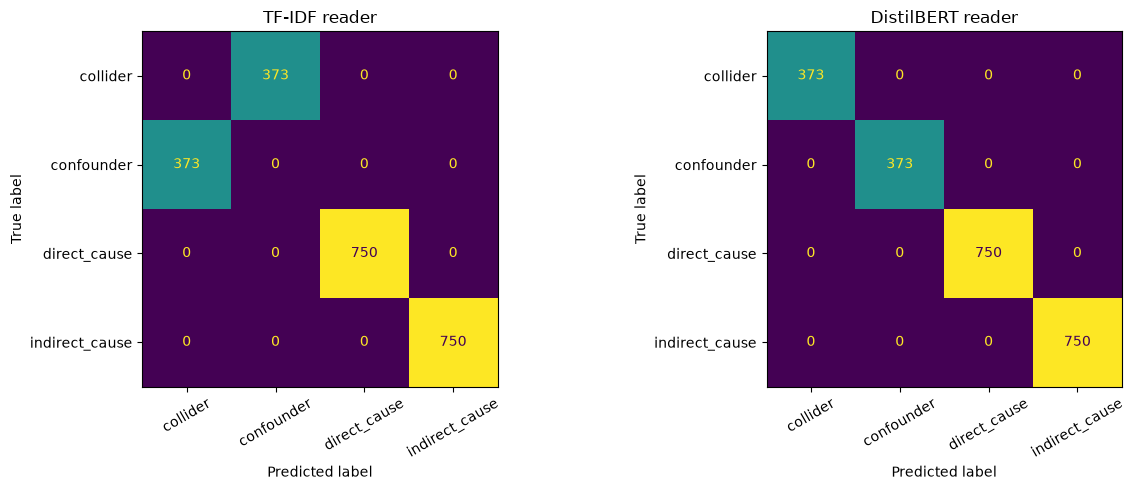

In [11]:
# ─── STEP 6: CONFUSION MATRICES (PARAPHRASING) ─────
cm_tfidf = confusion_matrix(paraphrasing["relation_true"], paraphrasing["relation_tfidf"], labels=RELATIONS)
cm_bert = confusion_matrix(paraphrasing["relation_true"], paraphrasing["relation_bert"], labels=RELATIONS)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(cm_tfidf, display_labels=RELATIONS).plot(ax=axes[0], colorbar=False, xticks_rotation=30)
axes[0].set_title("TF-IDF reader")
ConfusionMatrixDisplay(cm_bert, display_labels=RELATIONS).plot(ax=axes[1], colorbar=False, xticks_rotation=30)
axes[1].set_title("DistilBERT reader")
plt.tight_layout()
plt.savefig("../report/figures/reader_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

TF-IDF swaps collider and confounder. "A and B together cause some other variable(s)" (collider) and "Some
variable(s) cause(s) both A and B" (confounder) use almost the same words in a different order, and TF-IDF only
counts words. DistilBERT reads the words in order, so it can tell who causes whom.

In [15]:
# ─── STEP 7: SAVE AS CSV ─────
test_sets[["row_id", "test_set", "x", "y", "relation_regex", "relation_tfidf", "relation_bert", "bert_confidence"]].to_csv(
    "../data/processed/reader_predictions.csv", index=False)